In [1]:
TrainData_name = 'Mawqif_AllTargets_Train.csv'
TestData_name = 'Mawqif_AllTargets_Test.csv'

Enable_TargetSpecefic = 'Yes' #'No'
#selectedTarget = 'All'
selectedTarget = 'Covid Vaccine'
#selectedTarget = 'Digital Transformation'
#selectedTarget = 'Women empowerment'

Ex_name = 'STL_'+selectedTarget+"_Sent_Sarc"

#"UBC-NLP/MARBERT
#"aubmindlab/bert-base-arabertv02"
#"CAMeL-Lab/bert-base-arabic-camelbert-da"
model_name = "aubmindlab/bert-base-arabertv02-twitter"

# Environment Settings

In [2]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():    

    # Tell PyTorch to use the GPU.    
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))
    !nvidia-smi

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
We will use the GPU: NVIDIA GeForce RTX 2080 Ti
Mon Dec 26 14:58:33 2022       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 495.29.05    Driver Version: 495.29.05    CUDA Version: 11.5     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  NVIDIA GeForce ...  On   | 00000000:01:00.0 Off |                  N/A |
| 26%   30C    P8    21W / 260W |    264MiB / 11019MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
          

In [3]:
!pip install transformers datasets --quiet
!pip install farasapy==0.0.14 --quiet
!pip install PyArabic==0.6.14 --quiet 

In [4]:
# Import Basics
import pandas as pd
import numpy as np
import random
from tqdm.auto import tqdm
import pickle
import re
import os
import sys

from dataclasses import dataclass, field
from typing import Optional
import datasets
from datasets import ClassLabel, load_dataset, Dataset, DatasetDict
import string
from typing import Dict ,List


In [5]:
# Import for models
import transformers
from transformers import AutoTokenizer, AutoModel

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import torch.nn as nn


In [6]:
# Visualisation
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from matplotlib import rc

%matplotlib inline
%config InlineBackend.figure_format='retina'
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
rcParams['figure.figsize'] = 16, 10
tqdm.pandas()

# Prepare data

## Load data to colab drive

In [7]:
df = pd.read_csv(TrainData_name)
test_df = pd.read_csv(TestData_name)

## Label mapping

In [8]:
# Stance
mapping_stance = {'None': 2, 'Favor': 1, 'Against': 0}

df['stance'] = df['stance'].apply(lambda x: mapping_stance[x])
test_df['stance'] = test_df['stance'].apply(lambda x: mapping_stance[x])

# Sentiment
mapping_sent = {'Neutral': 2, 'Positive': 1, 'Negative': 0}

df['sentiment'] = df['sentiment'].apply(lambda x: mapping_sent[x])
test_df['sentiment'] = test_df['sentiment'].apply(lambda x: mapping_sent[x])

# Sarcasm
mapping_sarcasm = {"Yes": 1, "No": 0}

df['sarcasm'] = df['sarcasm'].apply(lambda x: mapping_sarcasm[x])
test_df['sarcasm'] = test_df['sarcasm'].apply(lambda x: mapping_sarcasm[x])

In [9]:
# Mapping targets

'''
mapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}

df['target'] = df['target'].apply(lambda x: mapping_targets[x])
test_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])
'''

"\nmapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}\n\ndf['target'] = df['target'].apply(lambda x: mapping_targets[x])\ntest_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])\n"

## Data Analysis

In [10]:
print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


In [ ]:
test_df.head()

In [ ]:
df['stance'].value_counts()

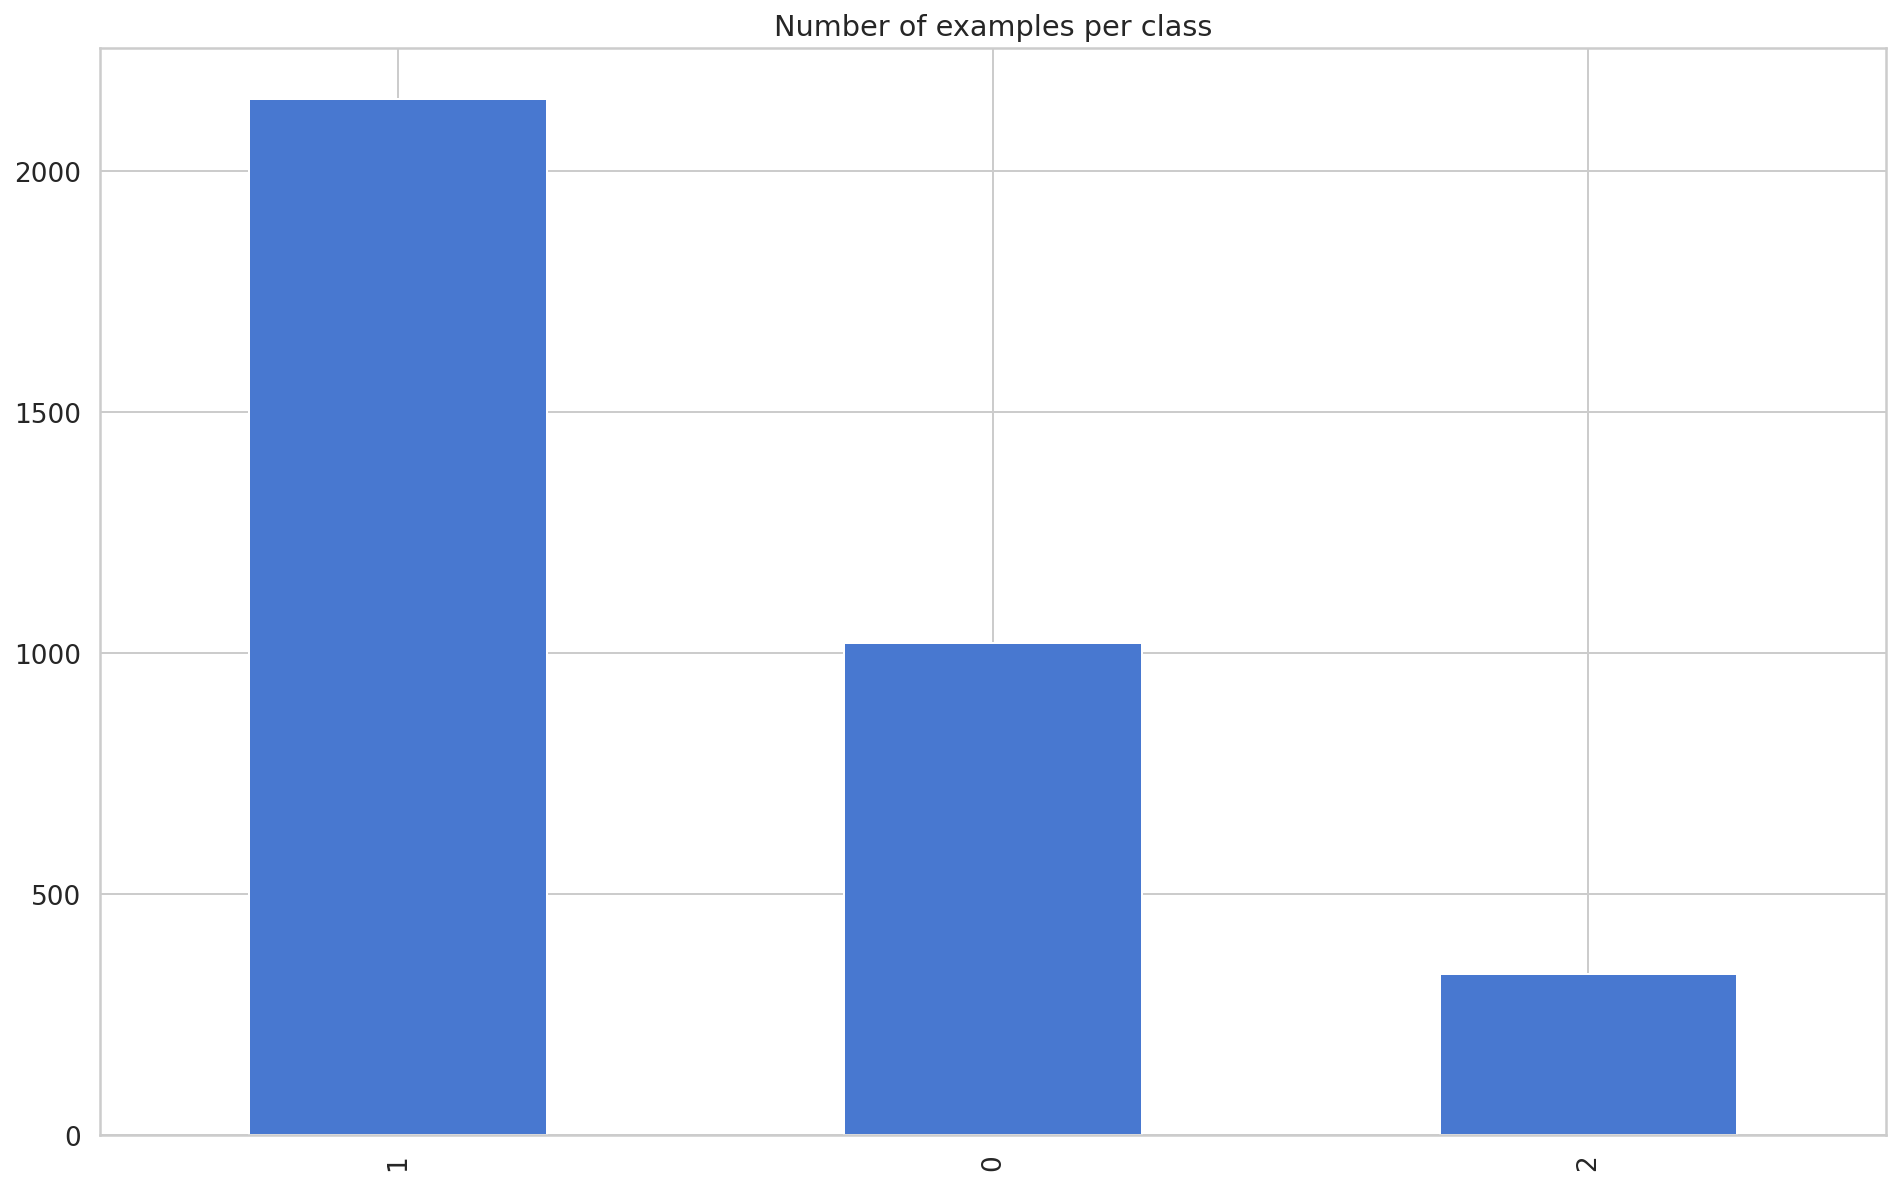

In [14]:
df['stance'].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Number of examples per class");

## Define specefic target

In [11]:
#Include only rows from specefic target
if Enable_TargetSpecefic == 'Yes':
  df= df[df['target'] == selectedTarget]
  test_df= test_df[test_df['target'] == selectedTarget]

print(df.shape)
print(test_df.shape)

(1167, 14)
(206, 14)


## Load data into Huggingface 

In [12]:
# load the dataset from pandas dataframe to Huggingface Dataset

tds = Dataset.from_pandas(df)
vds = Dataset.from_pandas(test_df)

loaded_datasets = DatasetDict()

loaded_datasets['train'] = tds
loaded_datasets['validation'] = vds

In [13]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date', '__index_level_0__'],
        num_rows: 1167
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date', '__index_level_0__'],
        num_rows: 206
    })
})

In [14]:
# Remove the extra column '__index_level_0__' when we convert from pandas to Huggingface
loaded_datasets = loaded_datasets.remove_columns(['__index_level_0__'])

In [19]:
# load_dataset is a function to load a dataset from a local dataset or other repositry int Hugging Face.
#loaded_datasets = load_dataset("csv", data_files={"train": '/content/'+TrainData_name, "validation": '/content/'+TestData_name})


## Preprocessing the tweets

### Regex preprocessing 

In [15]:
## Remove hashtags, URL, MENTION

def remove_hash_URL_MEN(text):
    #text = re.sub(r'#(\w+)','',text)
    text = re.sub(r'#',' ',text) #remove #
    text = re.sub(r'_',' ',text) #remove _
    text = re.sub(r'URL','',text)
    text = re.sub(r'MENTION','',text)
    return text

##  Remove punctuations

arabic_punctuations = '''`÷×؛<>()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ'''
english_punctuations = string.punctuation
punctuations_list = arabic_punctuations + english_punctuations

def remove_punctuations(text):
    translator = str.maketrans('', '', punctuations_list)
    return text.translate(translator)

##  Normalize_arabic

def normalize_arabic(text):
    text = re.sub("[إآ]", "ا", text)
    #text = re.sub("ى", "ي", text)
    #text = re.sub("ة", "ه", text)
    text = re.sub("گ", "ك", text)
    return text


## Remove_repeating_char

def remove_repeating_char(text):
    return re.sub(r'(.)\1+', r'\1', text)


# one4all preprocess

def processPost(tweet): 
    tweet['text']=remove_hash_URL_MEN(str(tweet['text']))

    #Replace @username with empty string
    tweet['text'] = re.sub('@[^\s]+', ' ', str(tweet['text']))
    
    #Convert www.* or https?://* to " "
    tweet['text'] = re.sub('((www\.[^\s]+)|(https?://[^\s]+))',' ',str(tweet['text']))
    
    #Replace #word with word
    #tweet['text'] = re.sub(r'#([^\s]+)', r'\1', str(tweet['text']))

    # remove punctuations
    #tweet['text']= remove_punctuations(str(tweet['text']))
    
    # normalize the tweet
    tweet['text']= normalize_arabic(str(tweet['text']))
    
    # remove repeated letters
    #tweet['text']=remove_repeating_char(str(tweet['text']))

    return tweet

In [16]:
# Regex preprocessing before tokenizing
loaded_datasets["train"] = loaded_datasets["train"].map(processPost)
loaded_datasets["validation"] = loaded_datasets["validation"].map(processPost)

In [17]:
# Sanity check on the dataset after Regex processing
list(loaded_datasets["validation"]['text'][0:20])

##Q: some emojis is not included in the vocab

['-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد..  -اطباء الكويت التطعيم بريء وامن..!!  تسويق وترقيع على حساب البشر غير معقول!!   لا للحظر  كورونا  التطعيم ',
 ' اخذت جرعه لقاح ولا باقي للاسف ماحولنا مراكز تطعيم اقرب شي بعد ١٥٠ كيلو وان اخذته انا غيري كثير من اهل الديره مايقدرون ياخذونه 🤷🏻\u200d♀️ ',
 ' لا للتطعيم الاجباري  ساحة الارادة  سأحضر السبت ساحة الارادة  زورت الجناسي زورت الشهادات الدراسيه زورت رخص القيادة شيصير اذا زورت شهادات تطعيم  كورونا الكويت  الكويت كلها تزوير بتزوير',
 '  يا ذكاء هو نفسه نفس تطعيم الانفلونزا اللي نأخذها كل موسم مع ذلك يجينا المرض و ما يمنعه لكن تكون اعراضه اخف و الايام تكون اقل باذن الله ، و مافي اي لقاح في العالم يحمي من الاصابة و بالنسبة للشيخ جته لكن بدون اعراض',
 ' يارجال اي لقاحات مظروبه تطعمنى وجاتنا كورونا وش الفايده.والله تطعيم الافلونزا بالمستوصف افضل من اللقاح',
 'لا توجد اي وفيات للاطفال من كورونا  ليش يتم تطعيمهم  اذا نحن الكبار طحنا شهر تعب وحرارة وهذا من اعراض اللقاح الطبيعي فـ كيف بأجسامهم الصغيرة  اشوف انه من الاجرام تطعيم الاطفال خصوص

### AraBERT preprocessing


In [18]:
!git clone https://github.com/aub-mind/arabert/

fatal: destination path 'arabert' already exists and is not an empty directory.


In [19]:
!pip install emoji==1.6.1

In [20]:
from arabert.preprocess import ArabertPreprocessor

#https://github.com/aub-mind/arabert/blob/master/preprocess.py
# Default values of parameters:
#ArabertPreprocessor(model_name: str, remove_html_markup: bool=True, replace_urls_emails_mentions: bool=True, strip_tashkeel: bool=True, 
#                    strip_tatweel: bool=True, insert_white_spaces: bool=True, remove_non_digit_repetition: bool=True, keep_emojis: bool=None,
#                    replace_slash_with_dash: bool=None, map_hindi_numbers_to_arabic: bool=None, apply_farasa_segmentation: bool=None)

arabert_prep = ArabertPreprocessor(model_name=model_name) #keep_emojis will be automatically set to True in AraBERT-twitter.


In [21]:
sample_tweet = test_df.iloc[10]
sample_tweet.text

'عزيزي ابوجرعتين لما يوصلك مسج الجرعة التنشيطية لا تتأخر والا سوف يتم حرمانك من (الإمتيازات) الممنوحة لك من وزارة الصحة  ملاحظة : الإمتيازات هي حقوقك الطبيعية والتي كنت تمارسها في العام 2019 وماقبل مثل الدخول للمجمعات والصالونات والاندية والسفر  #حاااحااا #لا_للتطعيم_الاجباري URL'

In [22]:
sample_text = arabert_prep.preprocess(sample_tweet.text)
sample_text

'عزيزي ابوجرعتين لما يوصلك مسج الجرعة التنشيطية لا تتأخر والا سوف يتم حرمانك من ( الإمتيازات ) الممنوحة لك من وزارة الصحة ملاحظة : الإمتيازات هي حقوقك الطبيعية والتي كنت تمارسها في العام 2019 وماقبل مثل الدخول للمجمعات والصالونات والاندية والسفر # حااحاا # لا _ للتطعيم _ الاجباري URL'

In [23]:
# Convert dataset to dataframe for easy manipulation to apply arabert_prep.preprocess
df_pandas_train = pd.DataFrame(loaded_datasets['train'])
df_pandas_valid = pd.DataFrame(loaded_datasets['validation'])

# Apply arabert_prep.preprocess
df_pandas_train['text'] = df_pandas_train['text'].apply(lambda x: arabert_prep.preprocess(x))
df_pandas_valid['text'] = df_pandas_valid['text'].apply(lambda x: arabert_prep.preprocess(x))

# Recover to HF dataset
loaded_datasets['train']=loaded_datasets['train'].from_pandas(df_pandas_train)
loaded_datasets['validation']=loaded_datasets['validation'].from_pandas(df_pandas_valid)

In [24]:
# Sanity check on the dataset after arabert processing
list(loaded_datasets['validation']['text'][0:20])

['- البي بي سي 10 دول اوروبية توقف تطعيم اوكسفورد . . - اطباء الكويت التطعيم بريء وامن . . ! ! تسويق وترقيع على حساب البشر غير معقول ! ! لا للحظر كورونا التطعيم',
 'اخذت جرعه لقاح ولا باقي للاسف ماحولنا مراكز تطعيم اقرب شي بعد 150 كيلو وان اخذته انا غيري كثير من اهل الديره مايقدرون ياخذونه 🤷 🏻 \u200d ♀',
 'لا للتطعيم الاجباري ساحة الارادة سأحضر السبت ساحة الارادة زورت الجناسي زورت الشهادات الدراسيه زورت رخص القيادة شيصير اذا زورت شهادات تطعيم كورونا الكويت الكويت كلها تزوير بتزوير',
 'يا ذكاء هو نفسه نفس تطعيم الانفلونزا اللي نأخذها كل موسم مع ذلك يجينا المرض و ما يمنعه لكن تكون اعراضه اخف و الايام تكون اقل باذن الله ، و مافي اي لقاح في العالم يحمي من الاصابة و بالنسبة للشيخ جته لكن بدون اعراض',
 'يارجال اي لقاحات مظروبه تطعمنى وجاتنا كورونا وش الفايده . والله تطعيم الافلونزا بالمستوصف افضل من اللقاح',
 'لا توجد اي وفيات للاطفال من كورونا ليش يتم تطعيمهم اذا نحن الكبار طحنا شهر تعب وحرارة وهذا من اعراض اللقاح الطبيعي ف كيف بأجسامهم الصغيرة اشوف انه من الاجرام تطعيم الاطفال خصوصا ان منا

In [25]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 1167
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 206
    })
})

# Building The Multi-Task Dataset

1. Define the tokenizer
2. Build and tokenize the stance_dataset
3. Build and tokenize the sentiment_dataset
4. Build and tokenize the sarcasm_dataset
5. Merge all datasets

In [27]:
## Parameters
max_length= 128 
seednum= 123

In [28]:
## Define the tokenizer        
tokenizer = AutoTokenizer.from_pretrained(model_name) #,add_prefix_space=True)

In [29]:
# A class for the task, inherit from dataclass where we specifie id, name ,type,num_labels
@dataclass
class Task:
    id: int
    name: str
    type: str
    num_labels: int

### Stance dataset

In [30]:
def load_stance_dataset():
    
    task_name = 'stance'
    num_labels =3  # {'None': 2, 'Favor': 1, 'Against': 0}
    task_id=1 # id of the task

    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets

    ## We need to rename the column to merge all the datasets later
    raw_datasets = raw_datasets.rename_column('stance', 'label') # rename column 


    # removing the none class
    # change: num_labels =2 
    #############################################
    '''
    df_pandas_train = pd.DataFrame(raw_datasets['train'])# convert dataset to dataframe for easy manipulation
    df_pandas_valid = pd.DataFrame(raw_datasets['validation'])

    df_pandas_train=df_pandas_train[df_pandas_train['label']!=0]# remove third class (None,label=0)
    df_pandas_valid=df_pandas_valid[df_pandas_valid['label']!=0]

    # mapping to start from zero
    mapping_stance = {1: 0, 2: 1}
    df_pandas_train['label'] = df_pandas_train['label'].apply(lambda x: mapping_stance[x])
    df_pandas_valid['label'] = df_pandas_valid['label'].apply(lambda x: mapping_stance[x])
    
    raw_datasets['train']=raw_datasets['train'].from_pandas(df_pandas_train)# recover to dataset
    raw_datasets['validation']=raw_datasets['validation'].from_pandas(df_pandas_valid)

    raw_datasets = raw_datasets.remove_columns(['__index_level_0__'])# this index is added by pandas when convertint to dataset (need to be removed)
    '''
    #############################################

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info



In [31]:
load_stance_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1167
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 206
 }),
 Task(id=1, name='stance', type='seq_classification', num_labels=3))

### Sentiment dataset

In [32]:
def load_sentiment_dataset():
    
    task_name = 'sentiment'
    num_labels =3 # {'Neutral': 2, 'Positive': 1, 'Negative': 0}
    task_id=2
  
    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sentiment', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )

    return train_dataset,validation_dataset,task_info


In [33]:
load_sentiment_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1167
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 206
 }),
 Task(id=2, name='sentiment', type='seq_classification', num_labels=3))

### Sarcasm dataset

In [34]:
def load_sarcasm_dataset():
    
    task_name = 'sarcasm'
    num_labels =2 # {"Yes": 1, "No": 0}
    task_id=3

    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result


    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sarcasm', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info

In [35]:
load_sarcasm_dataset()

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 1167
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 206
 }),
 Task(id=3, name='sarcasm', type='seq_classification', num_labels=2))

### Merging the 3 datasets

In [36]:
#def load_datasets(tokenizer, pad_to_max_length,max_seq_length,label_all_tokens ,preprocessing_num_workers,overwrite_cache):

def load_datasets():
    # load three datasets and merge it to have only one dataset 
    (
        seq_classification_train_dataset1,
        seq_classification_validation_dataset1,
        seq_classification_task1,
    ) = load_stance_dataset()

    (
        seq_classification_train_dataset2,
        seq_classification_validation_dataset2,
        seq_classification_task2,
    ) = load_sentiment_dataset()

    (
        seq_classification_train_dataset3,
        seq_classification_validation_dataset3,
        seq_classification_task3,
    ) = load_sarcasm_dataset()
 

    # Merge train datasets
    train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
        seq_classification_train_dataset2.to_pandas().append(
            seq_classification_train_dataset3.to_pandas()
            )
    )

    train_dataset = datasets.Dataset.from_pandas(train_dataset_df)
    train_dataset=train_dataset.shuffle(seed=seednum)

    # Append validation datasets
    validation_dataset = [
        seq_classification_validation_dataset1,
        seq_classification_validation_dataset2,
        seq_classification_validation_dataset3
    ]

    dataset = datasets.DatasetDict(
        {"train": train_dataset, "validation": validation_dataset}
    )
    
    tasks = [seq_classification_task1, seq_classification_task2, seq_classification_task3]

    return tasks, dataset


# CL Model

**Steps of CL model:**
1. Create attention heads with different layers
2. Define the encoder
3. Build CL model
--------

There is 3 tasks we can face in our CL implementation, so in evrey task an action is taken for:

**Sarcasm task:**
1. when the batch had a sarcasm task it's mean we are in the first level.
2. the 1, 2 and 3 level need  to be updated 
3. the NN of sarcasm will feed the NN of sentiment and the NN sentiment will feed the NN stance
4. the information (sarcasm) need to be passed throw 3 layers (hidden layer sarcasm, hidden layer sent, hidden layer stance )

**Sentiment task:**
1. when the batch had a sentiment task it's mean we are in the second level.
2. the 2 and 3 level need  to be updated 
3. the NN sentiment will feed the NN stance
4. the information (sentiment) need to be passed throw 2 layers ( hidden layer sentiment, hidden layer stance )

**Stance task:**
1. when the batch had a stance task it's mean we are in the third level.
2. the 3rd level need to be updated 
3. the NN stance will be updated
4. the information (stance) need to be passed throw it self ( hidden layer stance )
------
**NB:** in every level (task) we added 1 hidden layer (1 hidden layer for each task)

### Sentiment Head

In [37]:

class SequenceClassificationHeadSentiment(nn.Module):
    def __init__(self, hidden_size, num_labels,hidden_layer_sent,hidden_layer_sarc,hidden_layer_stan, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels

        self.classifier = nn.Linear(hidden_size, num_labels)
       
        # 3 layers need to be updated (sentiment hidden_layer, sarcasm hidden_layer, stance hidden_layer)
        self.hidden_layer_sent=hidden_layer_sent
        self.hidden_layer_sarc=hidden_layer_sarc
        self.hidden_layer_stan=hidden_layer_stan

        self._init_weights()

        
    def forward(self,pooled_output,labels=None, **kwargs):
        #pooled_output = self.dropout(pooled_output)
        # first case 3 level are changed
        output_level1=self.hidden_layer_sent(pooled_output)# pooed_output of the encode to sentiment hidden_layer
        output_level2=self.hidden_layer_sarc(output_level1)# sentiment hidden_layer to sarcasm hidden_layer
        output_level3=self.hidden_layer_stan(output_level2)# sarcasm to stance hidden_layer 
        
        logits = self.classifier(output_level1)
        

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
    

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            


### Sarcasm Head

In [38]:
class SequenceClassificationHeadSarcasm(nn.Module):
    def __init__(self, hidden_size, num_labels,hidden_layer_sarc,hidden_layer_stan, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels

        self.classifier = nn.Linear(hidden_size, num_labels)
        
        # 2 layers need to be updated ( sarcasm , stance)
        self.hidden_layer_sarc=hidden_layer_sarc
        self.hidden_layer_stan=hidden_layer_stan

        self._init_weights()

        
    def forward(self,pooled_output, labels=None, **kwargs):
        #pooled_output = self.dropout(pooled_output)
        output_level2=self.hidden_layer_sarc(pooled_output)# pooed_output of the encode to sarcasm hidden_layer 
        output_level3=self.hidden_layer_stan(output_level2)# sarcasm to stance hidden_layer
        
        logits = self.classifier(output_level2)
        
        loss = None
        if labels is not None:
            
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
    

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            


### Stance Head

In [39]:
class SequenceClassificationHeadStance(nn.Module):
    def __init__(self, hidden_size, num_labels,hidden_layer_stan, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        # 1 layers need to be updated stance
        self.hidden_layer_stan=hidden_layer_stan
        
        self._init_weights()


    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        
        output_level3=self.hidden_layer_stan(pooled_output)#pooed_output of the encode to stance hidden_layer
        
        logits = self.classifier(output_level3)
        

        loss = None
        if labels is not None:
            
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
             

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()

            

### STL class

In [40]:
class STL_Model(nn.Module):
    def __init__(self, model_name, tasks: List):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)
        self.hidden_layer_sent=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)
        self.hidden_layer_sarc=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)
        self.hidden_layer_stan=nn.Linear(self.encoder.config.hidden_size, self.encoder.config.hidden_size)

        self.output_heads = nn.ModuleDict()# creating dictionary that contien 3 task heads
        
        self._init_weights()# intiate the weights of the 3 hidden layers 
        for task in tasks:
            decoder = self._create_output_head(self.encoder.config.hidden_size, task,self.hidden_layer_stan,self.hidden_layer_sarc,self.hidden_layer_sent)
            # ModuleDict requires keys to be strings
            self.output_heads[str(task.id)] = decoder

    #staticmethod
    def _create_output_head(self,encoder_hidden_size: int, task,hidden_layer_stan,hidden_layer_sarc,hidden_layer_sent):
        if task.name == "stance":
            return SequenceClassificationHeadStance(encoder_hidden_size, task.num_labels,hidden_layer_stan)# this task need only 1 hidden_layer
        elif task.name == "sarcasm":
            return SequenceClassificationHeadSarcasm(encoder_hidden_size, task.num_labels,hidden_layer_sarc,hidden_layer_stan)# 2 hidden_layer for input to be updated
        elif task.name == "sentiment":
            return SequenceClassificationHeadSentiment(encoder_hidden_size, task.num_labels,hidden_layer_sent,hidden_layer_sarc,hidden_layer_stan)#  3 hidden_layer for input to be updated
        else:
            raise NotImplementedError()

    
    
    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        position_ids=None,
        head_mask=None,
        inputs_embeds=None,
        labels=None,
        task_ids=None,
        **kwargs,
    ):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            position_ids=position_ids,
            head_mask=head_mask,
            inputs_embeds=inputs_embeds,
        )

        #sequence_output, pooled_output = outputs[:2]# sequence_output  are the hidden representations of all tokens 
        pooled_output = outputs[1]

        # pooler layer takes the final hidden representation of the [CLS] token (this is a vector of size 768),
        #then applies a linear layer and tanh to it
        # pooled_output=[batch_size, 768]
        unique_task_ids_list = torch.unique(task_ids).tolist()# unique_task_ids_list=[1,2,3] ,task_ids=[1,2,3,1,1,2,1]

        loss_list = []
        logits = None
        for unique_task_id in unique_task_ids_list:
            #task_id_filter is used to filter only the task in hand from the batch for example 
            ## ask_id_filter for task=3 ,task_id_filter=tensor([False, False, True, False, False, False, False])

            task_id_filter = task_ids == unique_task_id 
            logits, task_loss = self.output_heads[str(unique_task_id)].forward(
                #sequence_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                pooled_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                labels=None if labels is None else labels[task_id_filter],
                attention_mask=attention_mask[task_id_filter],
            )

            if labels is not None:
                loss_list.append(task_loss)
                print("Task", unique_task_id, "Loss:", task_loss)

        # logits are only used for eval. and in case of eval the batch is not multi task
        # For training only the loss is used
        outputs = (logits, outputs[2:])

        if loss_list:
            loss = torch.stack(loss_list)
            outputs = (loss.mean(),) + outputs
            print("Loss Mean:", loss.mean())

        return outputs

    
    def _init_weights(self):
            

        self.hidden_layer_sent.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_sent.bias is not None:
            self.hidden_layer_sent.bias.data.zero_()
        
        
        self.hidden_layer_sarc.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_sarc.bias is not None:
            self.hidden_layer_sarc.bias.data.zero_()
            
        self.hidden_layer_stan.weight.data.normal_(mean=0.0, std=0.02)
        if self.hidden_layer_stan.bias is not None:
            self.hidden_layer_stan.bias.data.zero_()
            

# Training

In [41]:
# Import for trainer

from transformers import Trainer, DataCollatorWithPadding
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EvalPrediction,
    HfArgumentParser,
    PretrainedConfig,
    Trainer,
    TrainingArguments,
    default_data_collator,
    set_seed,
)
 

### Loading for training

In [42]:
# Load the multi task dataset
tasks, dataset = load_datasets()

# Build the multi task model
model = STL_Model(model_name,tasks)

## pad_to_multiple_of=8 --> this just for the GPU during training
data_collator = DataCollatorWithPadding(
                        tokenizer, pad_to_multiple_of=8
                    )

# Load the train dataset
train_dataset = dataset["train"]

# Load the validation dataset
validstance, validsarcasm, validsentiment = dataset['validation']


Some weights of the model checkpoint at aubmindlab/bert-base-arabertv02-twitter were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.decoder.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of BertModel were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dens

In [43]:
# We should have 1 merged dataset and 3 validation sets (one for each task)
dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
        num_rows: 3501
    })
    validation: [Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 206
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 206
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 206
    })]
})

In [44]:
dataset['train'] = dataset['train'].remove_columns(['__index_level_0__'])

In [45]:
train_dataset = train_dataset.remove_columns(['__index_level_0__'])

In [46]:
train_dataset

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
    num_rows: 3501
})

### Define metrics

In [47]:
def compute_metrics(p: EvalPrediction):
    preds = np.argmax(p.predictions[0],axis=1)
    target=p.label_ids
    #print(classification_report(target,preds))
 
    return {
            "precision": round(precision_score(target, preds, average='macro'),4),
            "recall": round(recall_score(target, preds, average='macro'),4),
            "macro_f1": round(f1_score(target, preds, average='macro'),4),
            "accuracy": round(accuracy_score(target, preds),4),
        }

### Logging to WANDB

In [48]:
#!pip install wandb

In [49]:
import wandb

In [50]:
wandb.login()

# API key:
# <removed>
# old: <removed>

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [51]:
wandb.init(project="CL", entity="nora_sa", name = Ex_name)

In [52]:
#%env "WANDB_NOTEBOOK_NAME" "Multi_Task"

### Define Trainer

In [53]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark = False

In [54]:
## NEW
training_args=transformers.TrainingArguments(
        output_dir="./models",
        overwrite_output_dir=True,
        learning_rate=2e-5, #1e-5
        adam_epsilon = 1e-8,
        #fp16 = True, # set this to True when using V100 or T4 GPU
        do_train=True,
        do_eval=True,
        num_train_epochs=20,
        per_device_train_batch_size = 8, #8, # up to 64 on 16GB with max len of 128
        per_device_eval_batch_size = 32, #default is 8
        gradient_accumulation_steps = 4, #4, # use this to scale batch size without needing more memory 
        #batch_size will be 32 (per_device_train_batch_size*gradient_accumulation_steps = 4*8)  
        #warmup_ratio = 0,
        #save_steps=500,
        logging_steps = 100, #default is 500
        evaluation_strategy = 'epoch', #'steps', #
        save_strategy = 'epoch',
        load_best_model_at_end = True, # this allows to automatically get the best model at the end based on whatever metric we want
        metric_for_best_model = 'macro_f1',
        greater_is_better = True,
        seed = 42,
        report_to="wandb",
        run_name = Ex_name # to log the experiment in wandb
    )

set_seed(training_args.seed)


#### Some calculations:

**total_train_batch_size** = args.train_batch_size * args.gradient_accumulation_steps * args.world_size

--> total_train_batch_size = 16 * 2 * 1 = 32

-------------

**num_update_steps_per_epoch** = len(train_dataloader) / args.gradient_accumulation_steps

**len(train_dataloader)** = #batches = #samples/ args.train_batch_size = 10506 / 16 = 656

--> num_update_steps_per_epoch = 656 / 2 = 328

-------

**max_steps** = math.ceil(args.num_train_epochs * num_update_steps_per_epoch)

--> max_steps = math.ceil(20 * 328) = 6560

-------


In [55]:
trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset=validstance,
    compute_metrics=compute_metrics,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

In [ ]:
trainer.train()


/home/eye/anaconda3/lib/python3.6/site-packages/transformers/optimization.py:309: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  FutureWarning,
***** Running training *****
  Num examples = 3501
  Num Epochs = 20
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 32
  Gradient Accumulation steps = 4
  Total optimization steps = 2180
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"


Task 1 Loss: tensor(1.1761, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.2189, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.6898, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0283, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.2847, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.2179, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.7173, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0733, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.3938, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.9956, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.6936, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0277, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.1143, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.0653, device='cuda:0', grad_fn=<NllLossBackw

Epoch,Training Loss,Validation Loss,Precision,Recall,Macro F1,Accuracy
0,0.651000,0.731515,0.713800,0.553300,0.549400,0.689300
1,0.473900,0.638452,0.740200,0.658100,0.672800,0.767000


Task 1 Loss: tensor(1.1528, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.3374, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.6804, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0569, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.2671, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.1238, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.6401, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0103, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.3930, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.1534, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.6574, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0680, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.1023, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.9892, device='cuda:0', grad_fn=<NllLossBackw

Task 1 Loss: tensor(1.0328, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.9785, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.7108, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.9074, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.8498, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.2393, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.2361, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.7751, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.0990, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.2642, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.2269, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.8633, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.2391, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.1497, device='cuda:0', grad_fn=<NllLossBackw

Task 1 Loss: tensor(1.2813, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.8697, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(1.0755, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.4068, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.6331, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0969, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.7123, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.5780, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.6895, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0805, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.4493, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.8160, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.9835, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(1.2366, device='cuda:0', grad_fn=<NllLossBackw

... (43 outputs left out)

Task 1 Loss: tensor(0.0183, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.6687, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.7985, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.4952, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.1346, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.1217, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0254, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.0939, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.0925, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.2403, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1664, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.0464, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.9350, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0298, device='cuda:0', grad_fn=<NllLossBackw

Task 1 Loss: tensor(0.0519, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.5165, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0199, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1961, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.3383, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.0554, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0548, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1495, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.2939, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.2740, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0107, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1929, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(1.2706, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.1146, device='cuda:0', grad_fn=<NllLossBackw

Loss Mean: tensor(0.4958, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.0533, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.6170, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0306, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.2336, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.0368, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.1472, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.1337, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1059, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.4000, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.3600, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0111, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.2571, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.1587, device='cuda:0', grad_fn=<NllLossBackward0>

Task 1 Loss: tensor(0.8101, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.7002, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0213, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.5105, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.2870, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.4702, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.1903, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.3158, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.1926, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(0.1100, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 3 Loss: tensor(0.0120, device='cuda:0', grad_fn=<NllLossBackward0>)
Loss Mean: tensor(0.1049, device='cuda:0', grad_fn=<MeanBackward0>)
Task 1 Loss: tensor(0.6395, device='cuda:0', grad_fn=<NllLossBackward0>)
Task 2 Loss: tensor(1.1276, device='cuda:0', grad_fn=<NllLossBackw

# Evaluation

In [ ]:
# Get predictions
preds_target = trainer.predict(validstance)

print(compute_metrics(preds_target))

In [ ]:
pt=preds_target

preds = np.argmax(pt.predictions[0],axis=1)
target=pt.label_ids

#print(preds)
#print(target)

report_test = classification_report(target, preds, zero_division=0, digits=4)
print(report_test)

In [ ]:
report_test = classification_report(target, preds, zero_division=0, digits=4, output_dict=True)
report_df = pd.DataFrame(report_test).transpose()

In [ ]:
cf_matrix = confusion_matrix(target, preds)
print(cf_matrix)

In [ ]:
#visualize confusion matrix

class_names = ['Against','Favor','None']

cm_df = np.asarray(cf_matrix).reshape(3,3)

print(cm_df.shape)
plt.figure(figsize = (10,10))
sns.heatmap(cm_df, annot=True, fmt='', cmap='Blues',annot_kws={"size": 16}, xticklabels=class_names, yticklabels=class_names)
plt.show()

# Write results

In [ ]:
# Change directory to save the results
path = "Results/"
%cd $path

In [ ]:
ex_report_test = classification_report(target, preds, target_names=class_names, zero_division=0, digits=4, output_dict=True)

print(ex_report_test)

df_report_test = pd.DataFrame(ex_report_test).transpose()

df_report_test.to_csv(Ex_name+'_Test_report.csv', sep=',')

# Save and Load the model

In [ ]:
#torch.save(model.state_dict(), '/kaggle/working/modell.pth')

In [ ]:
#my_model = MultiTaskModel_CL(model_name,tasks)
#my_model.load_state_dict(torch.load('/kaggle/working/modell.pth'))